# Physics in V-JEPA 2
**Accurate decoding → redundant representations → limited downstream control.**

This notebook follows the [presentation](presentation/vjepa_physics_draft.pdf).
Each experiment asks one question, shows the calculation, and explains what the result supports.

| Notebook | Presentation | Question |
|---|---|---|
| 1. Setup | Slides 1–2 | What is fitted and evaluated on each split? |
| 2. Layer-wise probing | Slide 3 | Where can we read out physics? |
| 3. Iterative nullspaces | Slide 4 | Does another readout survive removal? |
| 4. Multi-probe steering | Slides 5–6 | Do edits transfer to an independent readout? |
| 5. Centroid splines | Slides 7–8 | Can a curved edit improve the same readout? |
| 6. Through the predictor | Slides 9–11 | Does predicted motion actually change? |
| 7. Conclusions | Slide 12 | What have we established? |
| Appendices | Slides 13–15 + historical comparison | How do the edit and evaluation work? |

**Execution.** Run from this directory. The original pooled fitting/evaluation cells retain their
calculations, defaults, and output paths; rerunning them overwrites their generated results in
`results/nullspace/`, `results/steering/`, and `results/spline/`. The original PCA-replacement
experiment is still executable in Appendix C. The presentation uses the **offset-preserving**
spline follow-up instead, shown in Section 5 without changing the historical method.

New result-analysis cells read saved artifacts and keep their calculations in memory. Section 6
can run after setup alone: it recomputes the predictor statistics from saved per-clip predictions.
Fresh extraction and the optional predictor replay require a GPU allocation. Ordinary pooled fitting
needs a CPU compute allocation and the existing scratch feature caches. Stored outputs from unchanged
cells are historical; new analysis outputs are checked against the saved experiments.

## 1. Setup and data
**A** fits probes and splines; **B** selects regularization, layers, stopping, and knot counts;
**C** fits independent evaluators (with C-only cross-validation); **D** evaluates frozen choices.
Reuse the saved splits. Later follow-ups reuse an already-inspected D, so they are exploratory.


In [ ]:
%matplotlib inline
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from utils import (load_data, load_features, load_model, extract_features,
                   fit_probe, metrics, bootstrap_interval,
                   project_out, extend_removed_basis)

ROOT = Path.cwd()
SCRATCH = Path('/scratch/users/hmolin/jepa-interp')
FEATURES = SCRATCH / 'pooled_features'
CHECKPOINT = SCRATCH / 'checkpoints/vjepa2-vitl-fpc64-256'
ALPHAS = [1e-4, 1e-3, 1e-2, .1, 1, 10, 100, 1000, 10000]
RECOMPUTE_FEATURES = False  # Explicit opt-in; only on a GPU compute node.

data = load_data(ROOT)
for task, dataset in data.items():
    split_counts = {}
    for split_name in 'ABCD':
        in_split = dataset['split'] == split_name
        split_counts[split_name] = int(in_split.sum())
    print(task, split_counts)


direction {'A': 768, 'B': 220, 'C': 220, 'D': 292}
speed {'A': 768, 'B': 256, 'C': 256, 'D': 256}
acceleration {'A': 768, 'B': 256, 'C': 256, 'D': 256}


In [ ]:
def load_arrays(path):
    """Read named arrays and close the file immediately."""
    with np.load(path, allow_pickle=False) as saved:
        return {name: saved[name] for name in saved.files}


def error_reduction(edited_error, unedited_error):
    """Normalize aggregate target error by the matched no-edit baseline."""
    return 100 * (1 - np.mean(edited_error) / np.mean(unedited_error))


## 2. Layer-wise probing
### Extract or load features
We use the pinned V-JEPA 2 ViT-L checkpoint (see `checkpoint_manifest.json`), frozen in evaluation mode.
All 16 RGB frames stay at native 256×256 resolution. Apply ImageNet normalization, without resizing,
cropping, or repeating frames. Mean-pool all 2,048 space-time tokens after each of 24 blocks,
**before** final LayerNorm. Each cache contains `[video, layer, feature]` and ordered video IDs.

The existing shards have been consolidated once, without changing their values. There is no shard/resume
system in this notebook. Changing the checkpoint or preprocessing requires a new cache directory and
explicit recomputation; do not mix caches from different protocols.


In [ ]:
if RECOMPUTE_FEATURES:
    checkpoint_path = str(CHECKPOINT)
    model = load_model(checkpoint_path)
    FEATURES.mkdir(parents=True, exist_ok=True)

    for task, dataset in data.items():
        video_paths = dataset['videos']
        features = extract_features(model, video_paths)
        cache_path = FEATURES / f'{task}.npz'
        np.savez(cache_path, features=features, ids=dataset['ids'])
    del model

for task, dataset in data.items():
    cache_path = FEATURES / f'{task}.npz'
    dataset['x'] = load_features(cache_path, dataset['ids'])
    print(task, dataset['x'].shape)


direction (1500, 24, 1024)


speed (1536, 24, 1024)


acceleration (1536, 24, 1024)


### Fit on A; select regularization on B
Direction targets are `(sin θ, cos θ)`; speed and acceleration use their physical magnitudes.
Scikit-learn's Ridge fits an intercept, which centers using training data only. We do not scale individual
feature dimensions. The alpha grid and selection rule match the original experiment.


In [ ]:
probes = {}
validation = {}

for task, dataset in data.items():
    training_mask = dataset['split'] == 'A'
    validation_mask = dataset['split'] == 'B'
    training_targets = dataset['y'][training_mask]
    validation_targets = dataset['y'][validation_mask]
    probes[task] = []
    validation[task] = []

    for layer_index in range(24):
        training_features = dataset['x'][training_mask, layer_index]
        validation_features = dataset['x'][validation_mask, layer_index]
        probe, validation_score = fit_probe(
            training_features,
            training_targets,
            validation_features,
            validation_targets,
            task,
            ALPHAS,
        )
        probes[task].append(probe)
        validation[task].append(validation_score)

    print(task, 'fitted 24 probes')


direction fitted 24 probes


speed fitted 24 probes


acceleration fitted 24 probes


### Select the layer before scoring D
Retain the original rule: maximize mean validation R² across tasks. Use that common layer if each
variable has validation R² ≥ 0.5 there; otherwise use each task's minimum-validation-MAE layer.
Array indices are zero-based; all displayed block numbers are one-based.


In [ ]:
# Find the block with the best average validation R² across the three tasks.
r_squared_by_task = []
for task_scores in validation.values():
    r_squared_by_layer = [score['r2'] for score in task_scores]
    r_squared_by_task.append(r_squared_by_layer)

mean_r_squared_by_layer = np.mean(r_squared_by_task, axis=0)
common_layer = int(np.argmax(mean_r_squared_by_layer))

# Use a common block only if it performs adequately for every variable.
use_common_layer = True
for task_scores in validation.values():
    if task_scores[common_layer]['r2'] < 0.5:
        use_common_layer = False

selected = {}
for task, task_scores in validation.items():
    if use_common_layer:
        selected[task] = common_layer
    else:
        validation_errors = [score['mae'] for score in task_scores]
        selected[task] = int(np.argmin(validation_errors))

# Keep array indices in `selected`; convert to block numbers for display only.
selected_block_numbers = {}
for task, layer_index in selected.items():
    selected_block_numbers[task] = layer_index + 1
print('Selected blocks:', selected_block_numbers)


Selected blocks: {'direction': 19, 'speed': 19, 'acceleration': 19}


### Held-out scores and uncertainty
Score D only after selection. C is not fitted in this section. Bootstrap intervals resample test clips; they do not
capture training-seed uncertainty. Existing historical outputs are preserved: this cell keeps its results
in memory rather than overwriting them.


In [ ]:
results = {}
for task, dataset in data.items():
    training_mask = dataset['split'] == 'A'
    test_mask = dataset['split'] == 'D'
    training_targets = dataset['y'][training_mask]
    test_targets = dataset['y'][test_mask]

    # The constant baseline predicts the training-set mean for every test clip.
    training_mean = training_targets.mean(axis=0, keepdims=True)
    test_count = int(test_mask.sum())
    baseline_predictions = np.repeat(training_mean, test_count, axis=0)
    baseline_score = metrics(test_targets, baseline_predictions, task)

    layer_results = []
    for layer_index, probe in enumerate(probes[task]):
        test_features = dataset['x'][test_mask, layer_index]
        test_features = test_features.astype(float)
        predictions = probe.predict(test_features)
        predictions = predictions.reshape(test_targets.shape)

        test_score = metrics(test_targets, predictions, task)
        confidence_intervals = bootstrap_interval(test_targets, predictions, task)
        layer_results.append({
            'test': test_score,
            'ci': confidence_intervals,
            'prediction': predictions,
        })

    results[task] = {'layers': layer_results, 'constant': baseline_score}
    selected_layer = selected[task]
    selected_score = layer_results[selected_layer]['test']
    block_number = selected_layer + 1
    print(f"{task}: block {block_number}, "
          f"R²={selected_score['r2']:.3f}, MAE={selected_score['mae']:.3f}")


direction: block 19, R²=0.989, MAE=3.217


speed: block 19, R²=0.994, MAE=0.068


acceleration: block 19, R²=0.992, MAE=0.198


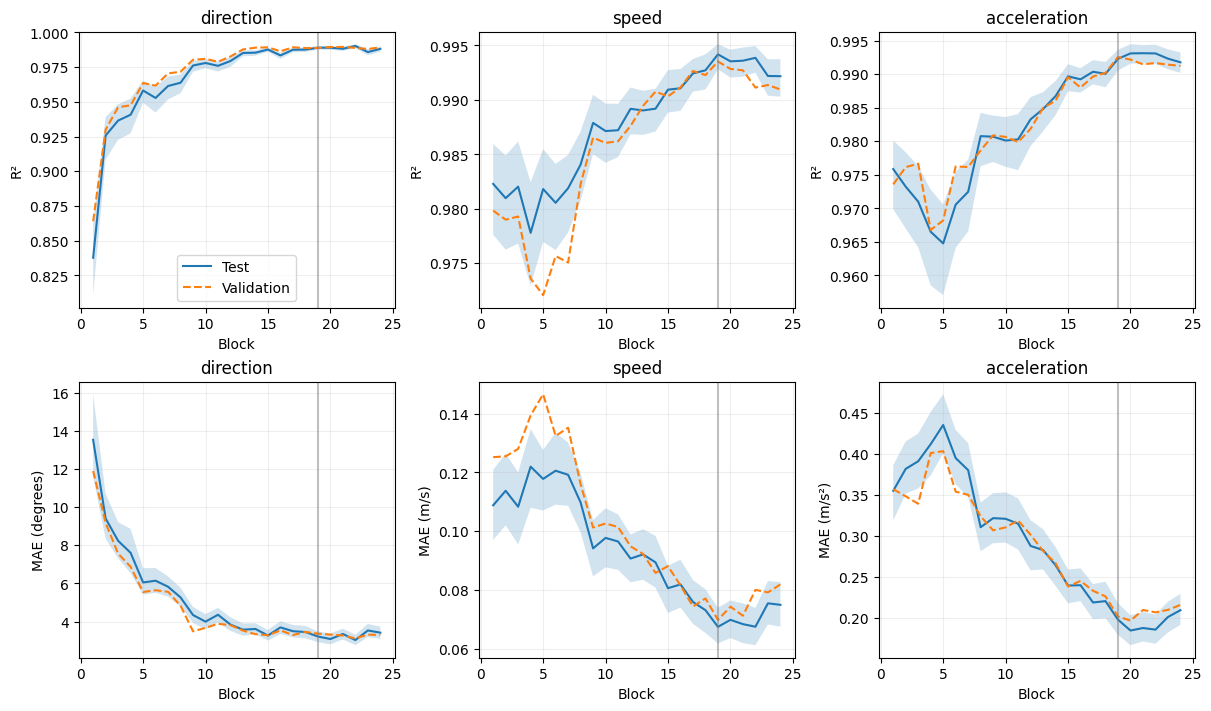

Constant-prediction baselines: {'direction': {'r2': -0.0047755943701653925, 'mae': 91.34845890410959}, 'speed': {'r2': 2.220446049250313e-16, 'mae': 0.9523809523809523}, 'acceleration': {'r2': 0.0, 'mae': 2.476190476190476}}


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7), layout='constrained')
units = dict(direction='degrees', speed='m/s', acceleration='m/s²')
for col, (task, result) in enumerate(results.items()):
    for row, metric in enumerate(['r2', 'mae']):
        ax = axes[row, col]
        values = [s['test'][metric] for s in result['layers']]
        bounds = np.array([s['ci'][metric] for s in result['layers']])
        ax.plot(range(1, 25), values, label='Test')
        ax.fill_between(range(1, 25), bounds[:, 0], bounds[:, 1], alpha=.2)
        ax.plot(range(1, 25), [s[metric] for s in validation[task]], '--', label='Validation')
        ax.axvline(selected[task] + 1, color='gray', alpha=.5)
        ax.set(title=task, xlabel='Block',
               ylabel='R²' if metric == 'r2' else f'MAE ({units[task]})')
        ax.grid(alpha=.2)
axes[0, 0].legend()
plt.show()
print('Constant-prediction baselines:', {t: r['constant'] for t, r in results.items()})


## 3. Iterative nullspace probing
We use **block 19**, a 1,024-dimensional mean-pooled representation, and remove at most
**256 dimensions per variable**. Each round fits a new linear probe to the remaining features.
A scalar probe removes at most one independent direction; the sine/cosine direction probe removes at most two.

For a centered feature vector $h$ and an orthonormal basis $Q$ of removed readout directions,
$h_{\mathrm{remaining}} = (I - QQ^\top)h$.
The implementation uses `features - (features @ Q) @ Q.T` for row-wise feature arrays,
without constructing a 1,024 × 1,024 projection matrix.

Fit probes on **A**, select their ridge regularization and stop using **B**, and evaluate on **D**
only after all sequences are fixed. **C** remains reserved for independent steering evaluators.
We center once using A, and do not standardize or renormalize after projection.

Stop after three consecutive probes with both low validation R² (≤0.1 for direction, ≤0.05 for scalars)
and validation MAE at least 90% of the training-mean baseline's validation MAE. Also stop at 256 removed
dimensions or when the next probe contributes no numerically independent direction. These are practical
stopping rules, not a claim of exact representational dimension. The point at rank zero is the original
probe; every subsequent point measures a **freshly fitted** probe after the indicated dimensions are removed.


In [ ]:
NULLSPACE_BLOCK = 19
MAX_REMOVED_DIMENSIONS = 256
STOPPING_PATIENCE = 3
MIN_BASELINE_ERROR_FRACTION = 0.9
R_SQUARED_THRESHOLDS = {'direction': 0.1, 'speed': 0.05, 'acceleration': 0.05}
NULLSPACE_OUTPUT = ROOT / 'results/nullspace'
NULLSPACE_OUTPUT.mkdir(parents=True, exist_ok=True)

nullspace_protocol = {
    'block': NULLSPACE_BLOCK,
    'maximum_removed_dimensions': MAX_REMOVED_DIMENSIONS,
    'stopping_patience': STOPPING_PATIENCE,
    'validation_r2_thresholds': R_SQUARED_THRESHOLDS,
    'minimum_baseline_error_fraction': MIN_BASELINE_ERROR_FRACTION,
    'ridge_alphas': ALPHAS,
    'fit_split': 'A',
    'validation_split': 'B',
    'test_split': 'D',
    'reserved_split': 'C',
    'centering': 'training mean; no feature scaling or renormalization',
}
protocol_path = NULLSPACE_OUTPUT / 'protocol.json'
protocol_path.write_text(json.dumps(nullspace_protocol, indent=2) + '\n')
print('Nullspace protocol saved before fitting.')


Nullspace protocol saved before fitting.


### Fit, project, and refit
At each round, the removed basis contains **all previously removed directions**. We project the original
centered features into its complement, fit a fresh probe, then add that probe's independent readout directions.
We retain the effective weights in the original centered coordinate system so the fitted sequence can be
inspected or reused later. No steering intervention is performed here.


In [ ]:
nullspace_runs = {}
layer_index = NULLSPACE_BLOCK - 1

for task, dataset in data.items():
    training_mask = dataset['split'] == 'A'
    validation_mask = dataset['split'] == 'B'
    layer_features = dataset['x'][:, layer_index].astype(float)
    training_mean = layer_features[training_mask].mean(axis=0)
    centered_features = layer_features - training_mean
    training_targets = dataset['y'][training_mask]
    validation_targets = dataset['y'][validation_mask]

    mean_target = training_targets.mean(axis=0, keepdims=True)
    baseline_predictions = np.repeat(mean_target, len(validation_targets), axis=0)
    baseline_score = metrics(validation_targets, baseline_predictions, task)
    minimum_baseline_error = MIN_BASELINE_ERROR_FRACTION * baseline_score['mae']

    feature_count = layer_features.shape[1]
    removed_basis = np.empty((feature_count, 0))
    consecutive_near_baseline = 0
    rounds = []

    while True:
        removed_dimensions = removed_basis.shape[1]
        remaining_features = project_out(centered_features, removed_basis)
        training_features = remaining_features[training_mask]
        validation_features = remaining_features[validation_mask]
        probe, validation_score = fit_probe(
            training_features,
            training_targets,
            validation_features,
            validation_targets,
            task,
            ALPHAS,
        )

        # Express the probe in the original centered feature coordinates.
        probe_weights = np.atleast_2d(probe.coef_)
        effective_weights = project_out(probe_weights, removed_basis)
        probe_bias = np.atleast_1d(probe.intercept_)
        rounds.append({
            'removed_dimensions': removed_dimensions,
            'alpha': float(probe.alpha),
            'validation': validation_score,
            'weights': effective_weights,
            'bias': probe_bias,
        })

        low_r_squared = validation_score['r2'] <= R_SQUARED_THRESHOLDS[task]
        baseline_level_error = validation_score['mae'] >= minimum_baseline_error
        if low_r_squared and baseline_level_error:
            consecutive_near_baseline += 1
        else:
            consecutive_near_baseline = 0

        if len(rounds) == 1 or len(rounds) % 10 == 0:
            print(f"{task}: removed {removed_dimensions} dimensions, "
                  f"validation R²={validation_score['r2']:.3f}, "
                  f"MAE={validation_score['mae']:.3f}")

        if consecutive_near_baseline >= STOPPING_PATIENCE:
            stop_reason = 'validation performance stayed near baseline'
            break
        if removed_dimensions >= MAX_REMOVED_DIMENSIONS:
            stop_reason = 'reached the dimension budget'
            break

        next_basis = extend_removed_basis(
            removed_basis, effective_weights, MAX_REMOVED_DIMENSIONS
        )
        if next_basis.shape[1] == removed_dimensions:
            stop_reason = 'no independent readout direction remains'
            break
        removed_basis = next_basis

        # Check that the accumulated basis really defines an orthogonal projection.
        gram_matrix = removed_basis.T @ removed_basis
        identity = np.eye(removed_basis.shape[1])
        np.testing.assert_allclose(gram_matrix, identity, atol=1e-8)

    nullspace_runs[task] = {
        'training_mean': training_mean,
        'removed_basis': removed_basis,
        'rounds': rounds,
        'validation_baseline': baseline_score,
        'stop_reason': stop_reason,
    }
    print(f"{task}: stopped at rank {removed_basis.shape[1]} — {stop_reason}")

# Save validation decisions before computing any nullspace test scores.
validation_decisions = {}
for task, run in nullspace_runs.items():
    round_scores = []
    for round_result in run['rounds']:
        round_scores.append({
            'removed_dimensions': round_result['removed_dimensions'],
            'alpha': round_result['alpha'],
            'validation': round_result['validation'],
        })
    validation_decisions[task] = {
        'stop_reason': run['stop_reason'],
        'validation_baseline': run['validation_baseline'],
        'rounds': round_scores,
    }
validation_path = NULLSPACE_OUTPUT / 'validation.json'
validation_path.write_text(json.dumps(validation_decisions, indent=2) + '\n')


direction: removed 0 dimensions, validation R²=0.989, MAE=3.367


direction: removed 18 dimensions, validation R²=0.876, MAE=10.898


direction: removed 38 dimensions, validation R²=0.695, MAE=24.290


direction: removed 58 dimensions, validation R²=0.525, MAE=34.524


direction: removed 78 dimensions, validation R²=0.404, MAE=45.305


direction: removed 98 dimensions, validation R²=0.285, MAE=50.897


... (54 outputs left out)

acceleration: removed 229 dimensions, validation R²=0.061, MAE=2.376


acceleration: removed 239 dimensions, validation R²=0.058, MAE=2.383


acceleration: stopped at rank 248 — validation performance stayed near baseline


106083

### Evaluate the fixed probe sequences on D
Now decode D with each already-fitted probe. We also save the final removed basis, training mean,
and effective weights/biases for every round. Test results do not change the stopping decisions.


In [ ]:
nullspace_scores = {}
for task, run in nullspace_runs.items():
    dataset = data[task]
    training_mask = dataset['split'] == 'A'
    test_mask = dataset['split'] == 'D'
    test_targets = dataset['y'][test_mask]
    test_features = dataset['x'][test_mask, layer_index].astype(float)
    centered_test_features = test_features - run['training_mean']

    mean_target = dataset['y'][training_mask].mean(axis=0, keepdims=True)
    constant_predictions = np.repeat(mean_target, len(test_targets), axis=0)
    test_baseline = metrics(test_targets, constant_predictions, task)
    round_scores = []
    test_predictions = []

    for round_result in run['rounds']:
        weights = round_result['weights']
        predictions = centered_test_features @ weights.T
        predictions = predictions + round_result['bias']
        test_score = metrics(test_targets, predictions, task)
        test_predictions.append(predictions)
        round_scores.append({
            'removed_dimensions': round_result['removed_dimensions'],
            'alpha': round_result['alpha'],
            'validation': round_result['validation'],
            'test': test_score,
        })

    nullspace_scores[task] = {
        'block': NULLSPACE_BLOCK,
        'stop_reason': run['stop_reason'],
        'test_baseline': test_baseline,
        'rounds': round_scores,
    }
    artifact_path = NULLSPACE_OUTPUT / f'{task}.npz'
    np.savez(
        artifact_path,
        training_mean=run['training_mean'],
        removed_basis=run['removed_basis'],
        weights=[item['weights'] for item in run['rounds']],
        biases=[item['bias'] for item in run['rounds']],
        removed_dimensions=[item['removed_dimensions'] for item in run['rounds']],
        alphas=[item['alpha'] for item in run['rounds']],
        test_ids=dataset['ids'][test_mask],
        test_targets=test_targets,
        test_predictions=test_predictions,
    )
    last_round = round_scores[-1]
    final_score = last_round['test']
    print(f"{task}: {last_round['removed_dimensions']} dimensions removed, "
          f"test R²={final_score['r2']:.3f}, MAE={final_score['mae']:.3f}")

scores_path = NULLSPACE_OUTPUT / 'scores.json'
scores_path.write_text(json.dumps(nullspace_scores, indent=2) + '\n')


direction: 220 dimensions removed, test R²=0.022, MAE=77.419


speed: 223 dimensions removed, test R²=0.035, MAE=0.936
acceleration: 248 dimensions removed, test R²=0.019, MAE=2.436


165253

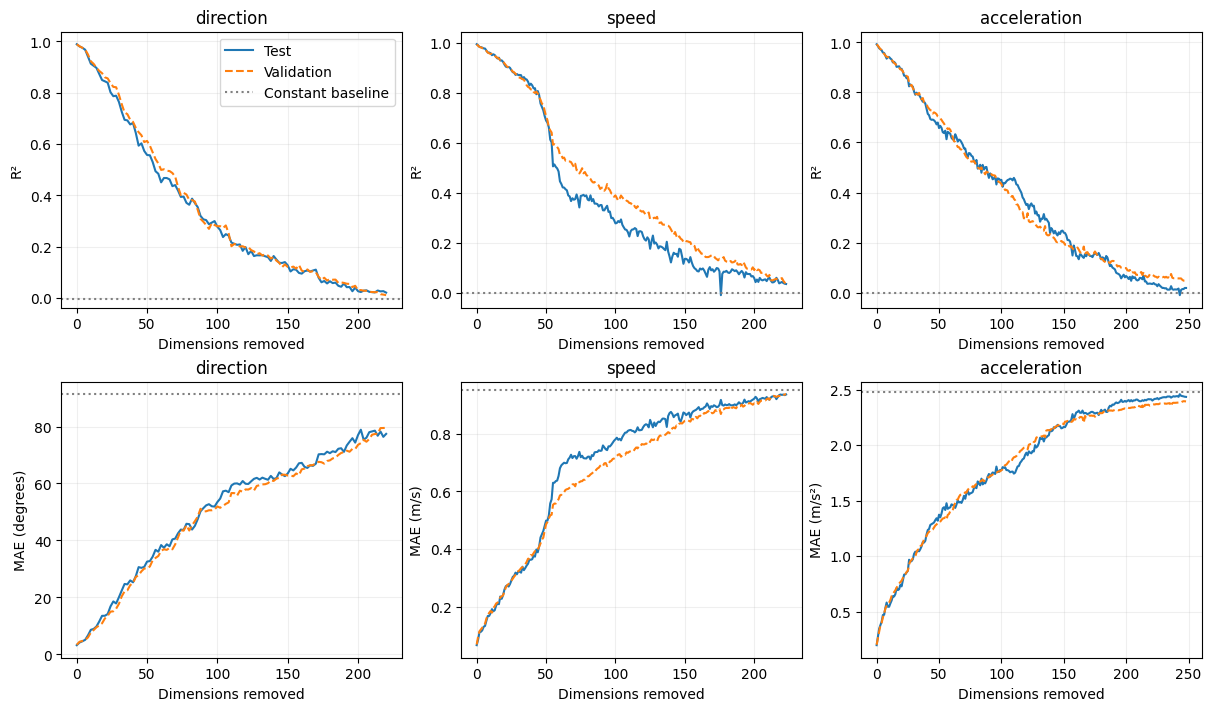

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7), layout='constrained')
for col, (task, run) in enumerate(nullspace_scores.items()):
    ranks = [point['removed_dimensions'] for point in run['rounds']]
    for row, metric in enumerate(['r2', 'mae']):
        ax = axes[row, col]
        ax.plot(ranks, [point['test'][metric] for point in run['rounds']], label='Test')
        ax.plot(ranks, [point['validation'][metric] for point in run['rounds']], '--', label='Validation')
        ax.axhline(run['test_baseline'][metric], color='gray', linestyle=':', label='Constant baseline')
        ax.set(title=task, xlabel='Dimensions removed',
               ylabel='R²' if metric == 'r2' else f'MAE ({units[task]})')
        ax.grid(alpha=.2)
axes[0, 0].legend()
fig.savefig(NULLSPACE_OUTPUT / 'curves.png', dpi=180)
fig.savefig(NULLSPACE_OUTPUT / 'curves.pdf')
plt.show()


### Reading the curves
The horizontal axis counts the cumulative rank removed, not the number of probes. A slow decline means
that new linear readouts remain available after earlier readouts are removed. A final plateau near baseline
means this fitting protocol no longer decodes the variable reliably; it does not prove that nonlinear
information is absent or identify an intrinsic dimensionality. Reaching 256 is a budget limit, not exhaustion.
These curves use one split and no rank-matched random-removal control, so they do not yet establish that the
removed directions are uniquely special. Earlier [audit findings](results/diagnostics/AUDIT.md) remain available
without rerunning the old control code here.


**Slide 4 takeaway.** The saved run stops at 220 / 223 / 248 removed dimensions for direction /
speed / acceleration. These are cumulative ranks under this stopping rule, not intrinsic dimensions.
Fresh test R² falls to about .022 / .035 / .019; direction still beats the constant angular-error
baseline. Redundant linear decoding is established; complete information erasure is not.


## 4. Multi-probe steering
We intervene on **pooled block-19 representations**, following the paper's probe-subspace procedure.
The encoder and all probes stay fixed during each intervention. No modified video is generated, and the
edited representation is not passed through later encoder blocks.

Construction uses the saved A-trained nullspace probes. Their effective weights act on features centered
by the saved A-training mean. The independent evaluators are fitted only on **C**, with five-fold
cross-validation inside C to choose regularization. **D** is used only after these choices are fixed.

For a subspace basis $Q$, we change coordinates $c$ by solving for the minimum-norm $\Delta c$:
$\min_{\Delta c}\|WQ\Delta c - (y^* - b - WQc)\|^2$.
Then $h^* = h + Q\Delta c$. The component orthogonal to $Q$ stays unchanged.

A low error on the construction probes verifies the optimization. The scientific question is whether
that change transfers to a separately trained decoder. Even successful transfer does not establish
control of downstream physical behavior.


### Fix the protocol and load construction probes
Use all eight 45°-spaced direction targets, and low/midpoint/high scalar targets within the supplied ranges.
The full sequence includes the terminal fitted probe from nullspace probing, not just probes whose
directions were subsequently removed. Record actual subspace rank separately from probe count.

We use the unregularized minimum-change least-squares solution, with a fixed numerical rank cutoff.
There is no search over steering strength or selection of the best probe count on D.


In [ ]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from utils import steering_basis, steer_features, target_errors

STEERING_BLOCK = 19
PROBE_COUNTS = [1, 2, 4, 8, 16, 32, 64]
CV_FOLDS = 5
CV_SEED = 20260929
STEERING_TARGETS = {
    'direction': [0, 45, 90, 135, 180, 225, 270, 315],
    'speed': [0.25, 2.125, 4.0],
    'acceleration': [0.25, 5.125, 10.0],
}
STEERING_OUTPUT = ROOT / 'results/steering'
STEERING_OUTPUT.mkdir(parents=True, exist_ok=True)

saved_protocol_path = ROOT / 'results/nullspace/protocol.json'
saved_nullspace_protocol = json.loads(saved_protocol_path.read_text())
assert saved_nullspace_protocol['block'] == STEERING_BLOCK

construction_probes = {}
probe_counts_by_task = {}
for task in data:
    saved_path = ROOT / f'results/nullspace/{task}.npz'
    with np.load(saved_path) as saved:
        construction_probes[task] = {
            'training_mean': saved['training_mean'],
            'weights': saved['weights'],
            'biases': saved['biases'],
        }
    available_count = len(construction_probes[task]['weights'])
    counts = [count for count in PROBE_COUNTS if count <= available_count]
    counts.append(available_count)
    probe_counts_by_task[task] = sorted(set(counts))

steering_protocol = {
    'block': STEERING_BLOCK,
    'targets': STEERING_TARGETS,
    'probe_counts': probe_counts_by_task,
    'construction_split': 'A; choices already selected using B',
    'evaluator_fit_split': 'C',
    'evaluator_cv_folds': CV_FOLDS,
    'evaluator_cv_seed': CV_SEED,
    'evaluator_ridge_alphas': ALPHAS,
    'evaluation_split': 'D',
    'solver': 'minimum-change least squares, rcond=1e-10',
    'basis_relative_rank_tolerance': 1e-10,
    'aggregation': 'equal weight to each fixed target and each test clip',
    'interpretation': 'pooled-representation readout transfer, not behavior steering',
}
protocol_path = STEERING_OUTPUT / 'protocol.json'
protocol_path.write_text(json.dumps(steering_protocol, indent=2) + '\n')
print('Steering targets and probe-count sweep fixed:', probe_counts_by_task)


Steering targets and probe-count sweep fixed: {'direction': [1, 2, 4, 8, 16, 32, 64, 111], 'speed': [1, 2, 4, 8, 16, 32, 64, 224], 'acceleration': [1, 2, 4, 8, 16, 32, 64, 249]}


### Fit independent evaluators using C only
Each evaluator is an ordinary ridge probe of the **unmodified** representation. Cross-validation scores
choose alpha using only C; then refit on all of C. These evaluators never see the construction probes,
steered examples, or D labels during training or regularization selection.


In [ ]:
evaluators = {}
evaluator_validation = {}
steering_layer_index = STEERING_BLOCK - 1

for task, dataset in data.items():
    evaluator_mask = dataset['split'] == 'C'
    evaluator_features = dataset['x'][evaluator_mask, steering_layer_index]
    evaluator_features = evaluator_features.astype(float)
    evaluator_targets = dataset['y'][evaluator_mask]

    splitter = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=CV_SEED)
    folds = list(splitter.split(evaluator_features))
    candidate_scores = []
    for alpha in ALPHAS:
        out_of_fold_predictions = np.empty_like(evaluator_targets)
        for training_indices, validation_indices in folds:
            fold_probe = Ridge(alpha=alpha, solver='cholesky')
            fold_probe.fit(
                evaluator_features[training_indices],
                evaluator_targets[training_indices],
            )
            fold_predictions = fold_probe.predict(evaluator_features[validation_indices])
            fold_target_shape = evaluator_targets[validation_indices].shape
            fold_predictions = fold_predictions.reshape(fold_target_shape)
            out_of_fold_predictions[validation_indices] = fold_predictions

        score = metrics(evaluator_targets, out_of_fold_predictions, task)
        candidate_scores.append({'alpha': alpha, 'cross_validation': score})

    best_candidate = min(candidate_scores, key=lambda item: item['cross_validation']['mae'])
    selected_alpha = best_candidate['alpha']
    evaluator = Ridge(alpha=selected_alpha, solver='cholesky')
    evaluator.fit(evaluator_features, evaluator_targets)
    evaluators[task] = evaluator
    evaluator_validation[task] = {
        'selected_alpha': selected_alpha,
        'candidates': candidate_scores,
    }

    evaluator_path = STEERING_OUTPUT / f'evaluator_{task}.npz'
    np.savez(
        evaluator_path,
        weights=evaluator.coef_,
        bias=evaluator.intercept_,
        alpha=selected_alpha,
        training_ids=dataset['ids'][evaluator_mask],
    )
    print(f"{task}: independent evaluator alpha={selected_alpha}, "
          f"C-only CV MAE={best_candidate['cross_validation']['mae']:.3f}")

evaluator_validation_path = STEERING_OUTPUT / 'evaluator_validation.json'
evaluator_validation_path.write_text(json.dumps(evaluator_validation, indent=2) + '\n')


direction: independent evaluator alpha=1, C-only CV MAE=4.668


speed: independent evaluator alpha=1, C-only CV MAE=0.094


acceleration: independent evaluator alpha=1, C-only CV MAE=0.285


4310

### Check the evaluators on unmodified D
Before interpreting any steering outcome, report ordinary predictive accuracy of the independent evaluators.
For each target, the no-steering baseline is the error between that target and the evaluator's clean prediction,
not the error against the clip's original label. Poor clean accuracy would limit the meaning of any steering result.


In [ ]:
clean_evaluation = {}
clean_predictions_by_task = {}
for task, dataset in data.items():
    test_mask = dataset['split'] == 'D'
    test_features = dataset['x'][test_mask, steering_layer_index].astype(float)
    test_targets = dataset['y'][test_mask]
    clean_predictions = evaluators[task].predict(test_features)
    clean_predictions = clean_predictions.reshape(test_targets.shape)
    clean_predictions_by_task[task] = clean_predictions
    clean_evaluation[task] = metrics(test_targets, clean_predictions, task)
    clean_score = clean_evaluation[task]
    print(f"{task}: independent evaluator on unmodified D — "
          f"R²={clean_score['r2']:.3f}, MAE={clean_score['mae']:.3f}")


direction: independent evaluator on unmodified D — R²=0.975, MAE=4.845
speed: independent evaluator on unmodified D — R²=0.987, MAE=0.100
acceleration: independent evaluator on unmodified D — R²=0.986, MAE=0.265


### Apply the fixed interventions and evaluate transfer
For each probe count, build the row-space basis once. Solve for each target separately, then add back
the construction training mean before passing the edited features to the independent evaluator.

We save errors for every clip/target, construction-probe errors, least-squares residuals, perturbation
norms, and error against the original labels. Large edits are a warning about off-distribution activations,
even if the evaluator reports the requested target. These are linear readout interventions; preserving
the orthogonal component does not guarantee preservation of other physical variables.


In [ ]:
steering_scores = {}
for task, dataset in data.items():
    test_mask = dataset['split'] == 'D'
    test_features = dataset['x'][test_mask, steering_layer_index].astype(float)
    test_targets = dataset['y'][test_mask]
    construction = construction_probes[task]
    training_mean = construction['training_mean']
    centered_test_features = test_features - training_mean
    source_norms = np.linalg.norm(centered_test_features, axis=1)
    safe_source_norms = np.maximum(source_norms, 1e-12)
    target_values = STEERING_TARGETS[task]

    # Encode physical target values in the construction probes' output coordinates.
    encoded_targets = []
    for target_value in target_values:
        if task == 'direction':
            target_radians = np.deg2rad(target_value)
            encoded_target = np.array([np.sin(target_radians), np.cos(target_radians)])
        else:
            encoded_target = np.array([target_value])
        encoded_targets.append(encoded_target)

    baseline_errors = []
    for encoded_target in encoded_targets:
        errors = target_errors(clean_predictions_by_task[task], encoded_target, task)
        baseline_errors.append(errors)
    baseline_errors = np.array(baseline_errors)

    sweep_results = []
    for probe_count in probe_counts_by_task[task]:
        weights = construction['weights'][:probe_count]
        biases = construction['biases'][:probe_count]
        basis = steering_basis(weights)
        rank = basis.shape[1]
        np.testing.assert_allclose(basis.T @ basis, np.eye(rank), atol=1e-8)
        original_orthogonal_component = project_out(centered_test_features, basis)

        stacked_weights = weights.reshape(-1, test_features.shape[1])
        stacked_biases = biases.reshape(-1)
        target_results = []
        all_predictions = []
        all_errors = []
        all_perturbation_norms = []
        all_relative_norms = []

        for target_value, encoded_target in zip(target_values, encoded_targets):
            steered_centered_features = steer_features(
                centered_test_features, weights, biases, basis, encoded_target
            )
            steered_orthogonal_component = project_out(steered_centered_features, basis)
            np.testing.assert_allclose(
                steered_orthogonal_component,
                original_orthogonal_component,
                atol=1e-8,
                rtol=1e-7,
            )

            steered_features = steered_centered_features + training_mean
            predictions = evaluators[task].predict(steered_features)
            predictions = predictions.reshape(test_targets.shape)
            errors = target_errors(predictions, encoded_target, task)
            original_label_score = metrics(test_targets, predictions, task)

            construction_predictions = steered_centered_features @ stacked_weights.T
            construction_predictions = construction_predictions + stacked_biases
            stacked_target = np.tile(encoded_target, probe_count)
            constraint_residuals = construction_predictions - stacked_target
            squared_residuals = constraint_residuals ** 2
            constraint_rmse = float(np.sqrt(squared_residuals.mean()))
            maximum_constraint_error = float(np.abs(constraint_residuals).max())
            construction_errors = target_errors(construction_predictions, encoded_target, task)

            perturbations = steered_centered_features - centered_test_features
            perturbation_norms = np.linalg.norm(perturbations, axis=1)
            relative_norms = perturbation_norms / safe_source_norms
            target_results.append({
                'target': target_value,
                'evaluator_target_mae': float(errors.mean()),
                'construction_target_mae': float(construction_errors.mean()),
                'constraint_rmse': constraint_rmse,
                'maximum_constraint_error': maximum_constraint_error,
                'mean_perturbation_norm': float(perturbation_norms.mean()),
                'mean_relative_perturbation_norm': float(relative_norms.mean()),
                'original_label_score': original_label_score,
            })
            all_predictions.append(predictions)
            all_errors.append(errors)
            all_perturbation_norms.append(perturbation_norms)
            all_relative_norms.append(relative_norms)

        mean_target_error = float(np.mean(all_errors))
        mean_relative_norm = float(np.mean(all_relative_norms))
        sweep_results.append({
            'probe_count': probe_count,
            'subspace_rank': rank,
            'mean_evaluator_target_mae': mean_target_error,
            'mean_relative_perturbation_norm': mean_relative_norm,
            'targets': target_results,
        })
        prediction_path = STEERING_OUTPUT / f'{task}_{probe_count:03d}_probes.npz'
        np.savez(
            prediction_path,
            basis=basis,
            targets=target_values,
            test_ids=dataset['ids'][test_mask],
            test_targets=test_targets,
            clean_predictions=clean_predictions_by_task[task],
            steered_predictions=all_predictions,
            target_errors=all_errors,
            baseline_target_errors=baseline_errors,
            perturbation_norms=all_perturbation_norms,
            relative_perturbation_norms=all_relative_norms,
        )
        print(f"{task}: {probe_count} probes, rank {rank}, "
              f"target MAE={mean_target_error:.3f}, relative edit norm={mean_relative_norm:.2f}")

    baseline_by_target = []
    for target_value, errors in zip(target_values, baseline_errors):
        baseline_by_target.append({'target': target_value, 'mae': float(errors.mean())})
    steering_scores[task] = {
        'clean_evaluator': clean_evaluation[task],
        'mean_no_steering_target_mae': float(baseline_errors.mean()),
        'no_steering_by_target': baseline_by_target,
        'sweep': sweep_results,
    }

scores_path = STEERING_OUTPUT / 'scores.json'
scores_path.write_text(json.dumps(steering_scores, indent=2) + '\n')


direction: 1 probes, rank 2, target MAE=72.239, relative edit norm=0.13


direction: 2 probes, rank 4, target MAE=33.748, relative edit norm=0.20


direction: 4 probes, rank 8, target MAE=4.525, relative edit norm=0.39


direction: 8 probes, rank 16, target MAE=4.002, relative edit norm=0.52


direction: 16 probes, rank 32, target MAE=3.733, relative edit norm=0.57


direction: 32 probes, rank 64, target MAE=3.636, relative edit norm=0.61


direction: 64 probes, rank 128, target MAE=3.571, relative edit norm=0.85


direction: 111 probes, rank 222, target MAE=7.531, relative edit norm=1.56
speed: 1 probes, rank 1, target MAE=0.889, relative edit norm=0.12
speed: 2 probes, rank 2, target MAE=0.446, relative edit norm=0.18
speed: 4 probes, rank 4, target MAE=0.267, relative edit norm=0.21
speed: 8 probes, rank 8, target MAE=0.118, relative edit norm=0.30
speed: 16 probes, rank 16, target MAE=0.078, relative edit norm=0.38
speed: 32 probes, rank 32, target MAE=0.080, relative edit norm=0.51
speed: 64 probes, rank 64, target MAE=0.068, relative edit norm=0.65


speed: 224 probes, rank 224, target MAE=0.069, relative edit norm=1.29
acceleration: 1 probes, rank 1, target MAE=2.271, relative edit norm=0.12
acceleration: 2 probes, rank 2, target MAE=1.079, relative edit norm=0.18
acceleration: 4 probes, rank 4, target MAE=0.667, relative edit norm=0.20
acceleration: 8 probes, rank 8, target MAE=0.347, relative edit norm=0.31
acceleration: 16 probes, rank 16, target MAE=0.224, relative edit norm=0.41
acceleration: 32 probes, rank 32, target MAE=0.201, relative edit norm=0.52
acceleration: 64 probes, rank 64, target MAE=0.176, relative edit norm=0.63


acceleration: 249 probes, rank 249, target MAE=0.559, relative edit norm=1.99


68108

### Target error versus probe count
The no-steering line measures the same clips and targets as every intervention. The single-probe case
is the first point of each curve. All targets receive equal weight. The second row shows edit size relative
to the norm of each A-centered source representation; it is not a guarantee of staying on the data manifold.


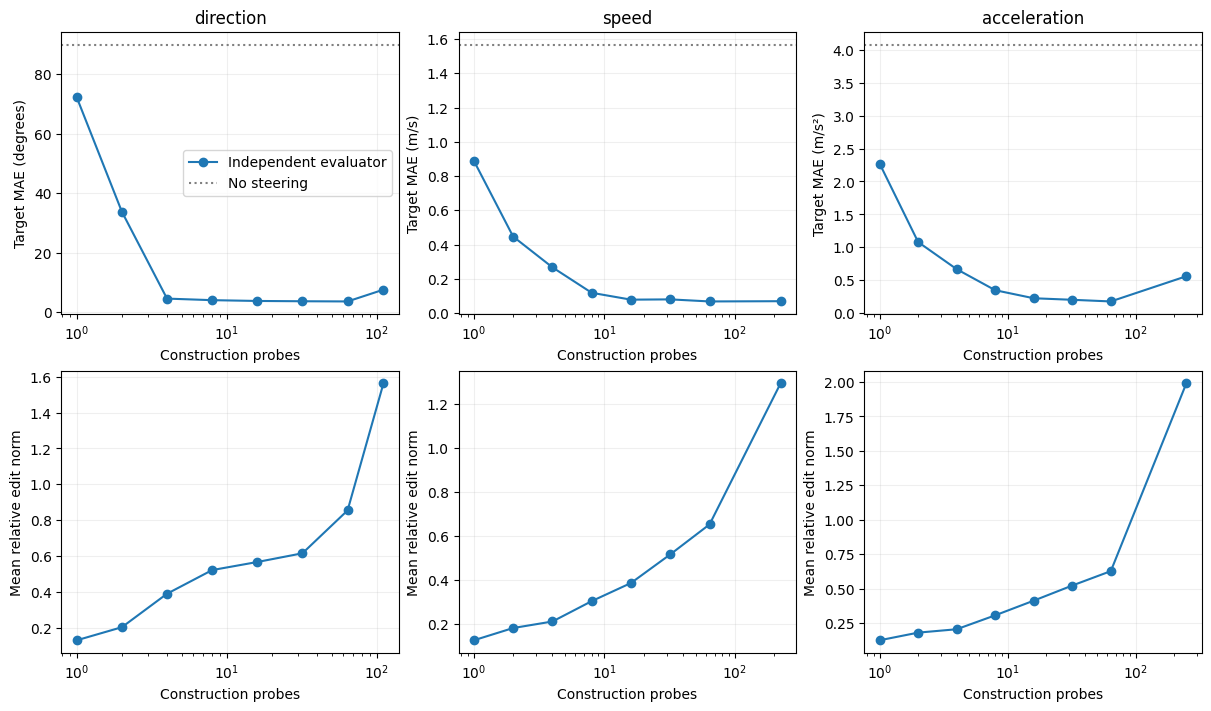

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7), layout='constrained')
steering_units = {'direction': 'degrees', 'speed': 'm/s', 'acceleration': 'm/s²'}
for col, (task, task_results) in enumerate(steering_scores.items()):
    sweep = task_results['sweep']
    counts = [point['probe_count'] for point in sweep]
    axes[0, col].plot(counts, [point['mean_evaluator_target_mae'] for point in sweep], 'o-', label='Independent evaluator')
    axes[0, col].axhline(task_results['mean_no_steering_target_mae'], linestyle=':', color='gray', label='No steering')
    axes[0, col].set(title=task, ylabel=f'Target MAE ({steering_units[task]})')
    axes[1, col].plot(counts, [point['mean_relative_perturbation_norm'] for point in sweep], 'o-')
    axes[1, col].set(ylabel='Mean relative edit norm')
    for ax in axes[:, col]:
        ax.set(xscale='log', xlabel='Construction probes')
        ax.grid(alpha=.2)
axes[0, 0].legend()
fig.savefig(STEERING_OUTPUT / 'curves.png', dpi=180)
fig.savefig(STEERING_OUTPUT / 'curves.pdf')
plt.show()


### Put the readout result on the presentation's scale
For each variable, use the same D clips and requested targets in both errors:

$$\text{readout error reduction} = 100\left(1 -
\frac{\text{mean edited absolute target error}}{\text{mean unedited absolute target error}}\right).$$

This is a **ratio of aggregate errors**, not a mean of per-clip percentages. Zero means no
improvement, 100% means exact target matching, and negative values mean the edit made things worse.
It is neither R² nor a measure of predictor velocity response. Sixteen probes is a fixed illustration,
not a setting selected on D. The preceding plots retain raw errors and edit sizes.


direction: 95.85% error reduction at 16 probes
speed: 95.01% error reduction at 16 probes
acceleration: 94.50% error reduction at 16 probes


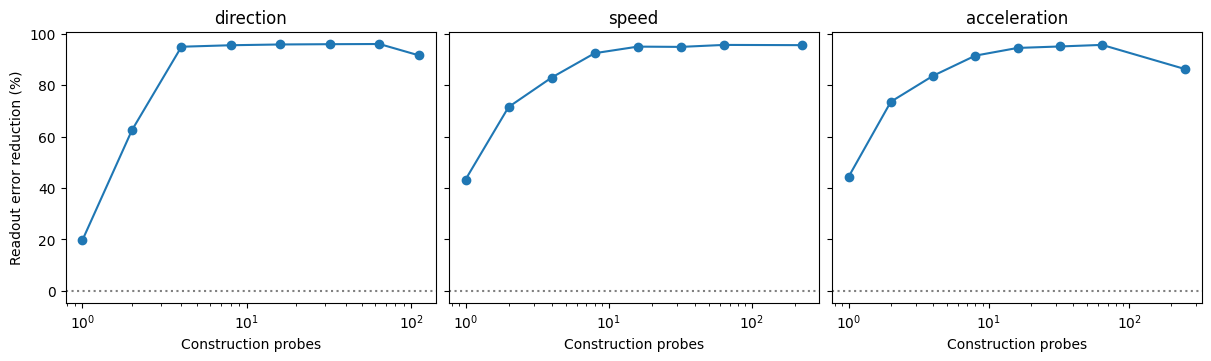

In [ ]:
# Reading the saved scores also makes this cell usable without repeating the fits.
pooled_steering = json.loads((ROOT / 'results/steering/scores.json').read_text())
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True, layout='constrained')
for ax, (task, scores) in zip(axes, pooled_steering.items()):
    baseline = scores['mean_no_steering_target_mae']
    counts = [point['probe_count'] for point in scores['sweep']]
    reductions = [error_reduction(point['mean_evaluator_target_mae'], baseline)
                  for point in scores['sweep']]
    ax.plot(counts, reductions, 'o-')
    ax.axhline(0, color='gray', linestyle=':')
    ax.set(title=task, xlabel='Construction probes', xscale='log')
    at_16 = reductions[counts.index(16)]
    print(f'{task}: {at_16:.2f}% error reduction at 16 probes')
axes[0].set_ylabel('Readout error reduction (%)')
plt.show()


### Inspect every target, including 90° direction
These curves expose target-specific failures that an average can hide. No probe count is selected from
the final-test outcomes. The saved JSON also contains the construction errors and least-squares residuals.


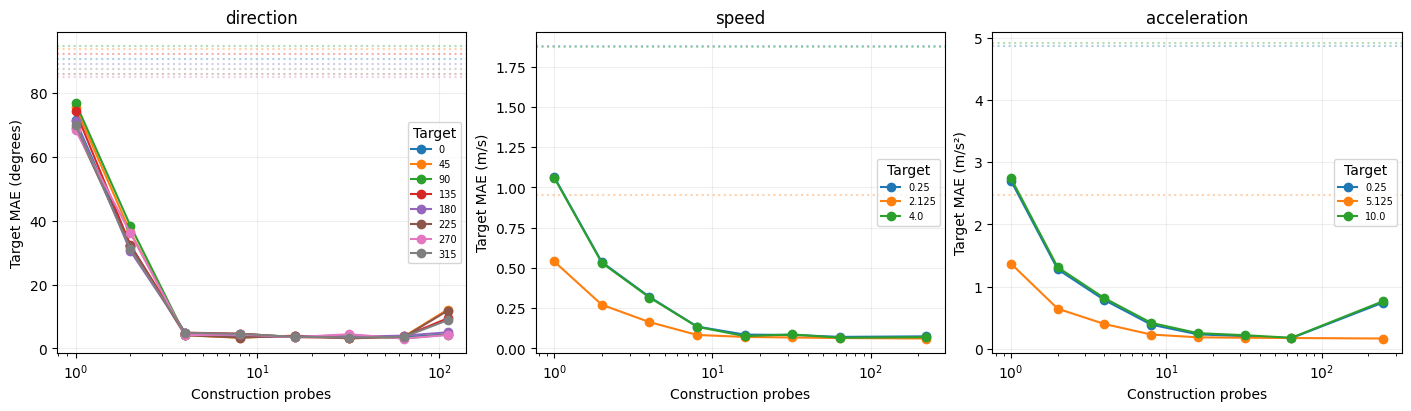

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout='constrained')
for ax, (task, task_results) in zip(axes, steering_scores.items()):
    sweep = task_results['sweep']
    counts = [point['probe_count'] for point in sweep]
    for target_index, target in enumerate(STEERING_TARGETS[task]):
        errors = [point['targets'][target_index]['evaluator_target_mae'] for point in sweep]
        line, = ax.plot(counts, errors, 'o-', label=str(target))
        baseline_error = task_results['no_steering_by_target'][target_index]['mae']
        ax.axhline(baseline_error, color=line.get_color(), linestyle=':', alpha=.35)
    ax.set(title=task, xscale='log', xlabel='Construction probes',
           ylabel=f'Target MAE ({steering_units[task]})')
    ax.legend(title='Target', fontsize=7)
    ax.grid(alpha=.2)
fig.savefig(STEERING_OUTPUT / 'targets.png', dpi=180)
plt.show()


### Interpreting steering
Construction-probe success alone follows from the optimization. Transfer to the C-trained evaluator
is stronger evidence of shared readout structure, but can still reflect common decoder sensitivities or
off-distribution activations. Large edits and failures on particular targets matter. This experiment has
no random-subspace control, no downstream encoder propagation, and no guarantee that unrelated physical
properties are preserved. It tests representation-level readout transfer, not physically coherent behavior.

Our C/D separation is stricter than the paper's evaluator trained on its test partition. Speed and
acceleration extend the paper's direction-steering experiment. D has been inspected in earlier probing
experiments; this is a fixed-protocol follow-up, not a newly untouched benchmark.


## 5. Centroid splines
**Question:** can we steer with a curve through label-conditioned activation centroids?
Fit PCA64 and centroid curves on A; select 8, 12, or 16 knots on B. Direction is periodic;
speed and acceleration use natural cubic splines. The next cells keep the original fitting code
and saved model format. Its protocol describes the historical replacement evaluation in Appendix C.

The presentation reuses these fits but changes the edit. If $f(s)$ is the source centroid and
$f(t)$ is the target centroid in PCA coordinates, add their difference:

$$h_{\mathrm{edited}} = h + [f(t)-f(s)]P.$$

Here the rows of $P$ are the PCA directions. This retains the offset from the source centroid,
preserves the PCA orthogonal complement, and gives exactly zero edit when source equals target.
It uses the **known source label**. These guarantees do not imply full-manifold membership or
preservation of every unrelated physical property.


In [ ]:
from itertools import combinations
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from utils import fit_centroid_spline, replace_pca_coordinates, target_errors

SPLINE_OUTPUT = ROOT / 'results/spline'
SPLINE_OUTPUT.mkdir(parents=True, exist_ok=True)
SPLINE_BLOCK = 19
PCA_DIMENSIONS = 64
KNOT_CANDIDATES = [8, 12, 16]
WAYPOINT_COUNT = 21
SPLINE_BOUNDS = {'direction': [0., 360.], 'speed': [.25, 4.], 'acceleration': [.25, 10.]}
# Reuse Section 4's fixed physical targets and independent evaluator weights.
multiprobe_protocol = json.loads((ROOT / 'results/steering/protocol.json').read_text())
assert multiprobe_protocol['block'] == SPLINE_BLOCK
spline_targets = multiprobe_protocol['targets']
spline_protocol = {
    'block': SPLINE_BLOCK,
    'pca_dimensions': PCA_DIMENSIONS,
    'fit_split': 'A',
    'selection_split': 'B',
    'selection_metric': 'mean squared PCA reconstruction error at the known B label',
    'knot_candidates': KNOT_CANDIDATES,
    'bounds': SPLINE_BOUNDS,
    'targets': spline_targets,
    'binning': 'nearest uniformly spaced label anchor; boundary bins have half width',
    'interpolation': 'exact centroid interpolation; periodic direction, natural scalars',
    'coordinates': 'physical labels; no source-position inference',
    'paths': 'all unordered fixed-target pairs; shortest direction arc, +180 for ties',
    'waypoints': WAYPOINT_COUNT,
    'intervention': 'replace top-64 PCA coordinates; preserve orthogonal component for both methods',
    'evaluator': 'saved Section 4 C-trained evaluators; no refitting',
    'test_split': 'D',
    'geometry_diagnostic': 'nearest A activation in PCA coordinates, not full-space naturalness',
}
(SPLINE_OUTPUT / 'protocol.json').write_text(json.dumps(spline_protocol, indent=2) + '\n')

1265

### Fit PCA and choose the centroid resolution on A/B
Fit PCA once per variable on A. Average within bins around fixed label anchors, including scalar
range endpoints; boundary centroids therefore summarize one-sided neighborhoods, not exact endpoint
examples. Choose knot count by predicting B's PCA coordinates from its known label. No C/D features
or evaluator scores enter this selection, and we do not refit on B afterwards.

Direction uses one pooled curve across the two motion regimes. This is an explicit simplification;
a conditional average need not describe every regime or lie on the true data manifold.

In [ ]:
spline_models = {}
spline_validation = {}
layer_index = SPLINE_BLOCK - 1
for task, dataset in data.items():
    train_mask = dataset['split'] == 'A'
    validation_mask = dataset['split'] == 'B'
    train_features = dataset['x'][train_mask, layer_index].astype(float)
    validation_features = dataset['x'][validation_mask, layer_index].astype(float)
    if task == 'direction':
        angles = np.arctan2(dataset['y'][:, 0], dataset['y'][:, 1])
        labels = np.rad2deg(angles) % 360
    else:
        labels = dataset['y'][:, 0]

    pca = PCA(n_components=PCA_DIMENSIONS, svd_solver='full')
    train_coordinates = pca.fit_transform(train_features)
    validation_coordinates = pca.transform(validation_features)
    candidates = []
    fitted_curves = {}
    for knot_count in KNOT_CANDIDATES:
        fitted = fit_centroid_spline(
            train_coordinates, labels[train_mask], task, knot_count, SPLINE_BOUNDS[task]
        )
        curve, anchors, centroids, counts = fitted
        predicted_coordinates = curve(labels[validation_mask])
        residuals = validation_coordinates - predicted_coordinates
        reconstruction_mse = float(np.mean(residuals ** 2))
        candidates.append({'knots': knot_count, 'validation_mse': reconstruction_mse})
        fitted_curves[knot_count] = fitted

    best = min(candidates, key=lambda candidate: candidate['validation_mse'])
    curve, anchors, centroids, counts = fitted_curves[best['knots']]
    neighbors = NearestNeighbors(n_neighbors=1).fit(train_coordinates)
    validation_distances, _ = neighbors.kneighbors(validation_coordinates)
    with np.load(ROOT / f'results/steering/evaluator_{task}.npz') as saved:
        np.testing.assert_array_equal(saved['training_ids'], dataset['ids'][dataset['split'] == 'C'])
        evaluator_weights = saved['weights'].copy()
        evaluator_bias = saved['bias'].copy()

    spline_models[task] = {
        'pca': pca, 'curve': curve, 'anchors': anchors, 'centroids': centroids,
        'neighbors': neighbors, 'evaluator_weights': evaluator_weights,
        'evaluator_bias': evaluator_bias,
    }
    spline_validation[task] = {
        'selected_knots': best['knots'], 'candidates': candidates,
        'explained_variance_fraction': float(pca.explained_variance_ratio_.sum()),
        'bin_counts': counts.tolist(),
        'mean_B_nearest_A_distance': float(validation_distances.mean()),
    }
    np.savez(
        SPLINE_OUTPUT / f'model_{task}.npz',
        pca_mean=pca.mean_, pca_components=pca.components_,
        spline_knots=curve.x, spline_coefficients=curve.c,
        anchors=anchors, centroids=centroids, bin_counts=counts,
        training_ids=dataset['ids'][train_mask], validation_ids=dataset['ids'][validation_mask],
    )
    print(task, 'knots:', best['knots'], 'PCA variance:', round(pca.explained_variance_ratio_.sum(), 3))

# Freeze all fitting decisions before evaluating D.
(SPLINE_OUTPUT / 'validation.json').write_text(json.dumps(spline_validation, indent=2) + '\n')

direction knots: 12 PCA variance: 0.981


speed knots: 8 PCA variance: 0.982


acceleration knots: 12 PCA variance: 0.979


1688

### Inspect the fitted curves
The first three PCA coordinates are a visualization of the 64-dimensional fit. Points mark A's
centroids; the dashed chord connects the first and last fixed targets for scalars, and 0° to 180°
for direction. A curved picture alone does not establish better steering.

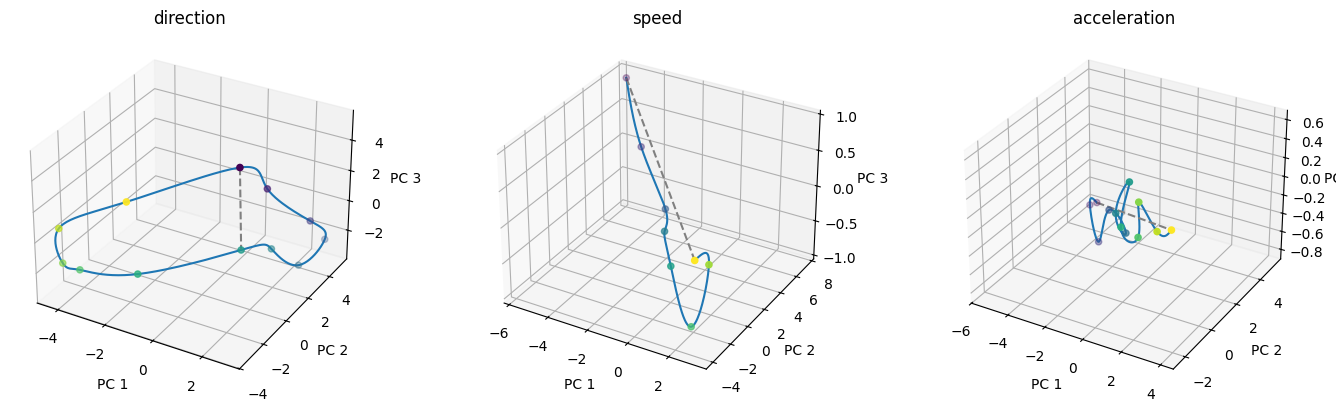

In [ ]:
fig = plt.figure(figsize=(14, 4), layout='constrained')
for col, (task, model) in enumerate(spline_models.items()):
    ax = fig.add_subplot(1, 3, col + 1, projection='3d')
    lower, upper = SPLINE_BOUNDS[task]
    labels = np.linspace(lower, upper, 300)
    coordinates = model['curve'](labels)
    centroids = model['centroids']
    ax.plot(*coordinates[:, :3].T, linewidth=1.5)
    ax.scatter(*centroids[:, :3].T, c=model['anchors'], cmap='viridis', s=20)
    endpoints = [0., 180.] if task == 'direction' else [lower, upper]
    chord = model['curve'](endpoints)
    ax.plot(*chord[:, :3].T, '--', color='gray')
    ax.set(title=task, xlabel='PC 1', ylabel='PC 2', zlabel='PC 3')
fig.savefig(SPLINE_OUTPUT / 'geometry.png', dpi=180)
plt.show()

### Apply the offset-preserving edit to the frozen D examples
Load exactly the A-fit, B-selected models and C-trained evaluators used by the presentation.
Keep the scalar readout's output axis explicit: weights have shape `[output, channel]`.
Each task's `features` below has shape `[D clip, 1024]`; the curve returns 64 PCA coordinates.

The tiny `offset_edit` helper is the existing implementation from the follow-up script.
We also show its arithmetic here: `features + (target_centroid - source_centroid) @ components`.
The checks compare every fixed-target prediction with `results/spline_offset_v1/`, not just rounded means.


In [ ]:
from scipy.interpolate import PPoly
from misc.evaluate_pooled_spline_offset import encoded, offset_edit
from utils import target_errors

# This cell can also follow setup + cached-feature loading, without refitting PCA.
offset_inputs = {}
for task, dataset in data.items():
    model = load_arrays(ROOT / f'results/spline/model_{task}.npz')
    evaluator = load_arrays(ROOT / f'results/steering/evaluator_{task}.npz')
    reference = load_arrays(ROOT / f'results/spline_offset_v1/evaluation_{task}.npz')
    test_mask = dataset['split'] == 'D'
    np.testing.assert_array_equal(model['training_ids'], dataset['ids'][dataset['split'] == 'A'])
    np.testing.assert_array_equal(model['validation_ids'], dataset['ids'][dataset['split'] == 'B'])
    np.testing.assert_array_equal(evaluator['training_ids'], dataset['ids'][dataset['split'] == 'C'])
    np.testing.assert_array_equal(reference['test_ids'], dataset['ids'][test_mask])
    np.testing.assert_allclose(reference['test_targets'], dataset['y'][test_mask], atol=1e-12)
    source_labels = reference['source_labels']  # Known physical labels, in saved D order.
    np.testing.assert_allclose(np.array([encoded(s, task) for s in source_labels]),
                               dataset['y'][test_mask], atol=1e-12)
    curve = PPoly(model['spline_coefficients'], model['spline_knots'],
                  extrapolate='periodic' if task == 'direction' else False)
    offset_inputs[task] = {
        'features': dataset['x'][test_mask, 18].astype(float),
        'components': model['pca_components'], 'mean': model['pca_mean'],
        'curve': curve, 'source': curve(source_labels),
        'weights': np.atleast_2d(evaluator['weights']), 'bias': evaluator['bias'],
        'reference': reference,
    }


In [ ]:
offset_results = {}
for task, inputs in offset_inputs.items():
    features = inputs['features']
    components = inputs['components']
    source = inputs['source']
    curve = inputs['curve']
    weights, bias = inputs['weights'], inputs['bias']
    original_coordinates = (features - inputs['mean']) @ components.T
    original_offset = original_coordinates - source
    original_complement = features - inputs['mean'] - original_coordinates @ components
    clean_predictions = features @ weights.T + bias
    np.testing.assert_array_equal(offset_edit(features, components, source, source), features)

    predictions, errors, baselines = [], [], []
    for target in inputs['reference']['fixed_targets']:
        destination = curve(target)
        edited = offset_edit(features, components, source, destination)
        edited_coordinates = (edited - inputs['mean']) @ components.T
        np.testing.assert_allclose(edited_coordinates - destination, original_offset, atol=1e-9)
        complement = edited - inputs['mean'] - edited_coordinates @ components
        np.testing.assert_allclose(complement, original_complement, atol=1e-9)
        prediction = edited @ weights.T + bias
        predictions.append(prediction)
        errors.append(target_errors(prediction, encoded(target, task), task))
        baselines.append(target_errors(clean_predictions, encoded(target, task), task))

    np.testing.assert_allclose(predictions, inputs['reference']['fixed_target_predictions'], atol=1e-9)
    np.testing.assert_allclose(errors, inputs['reference']['fixed_target_errors'], atol=1e-9)
    offset_results[task] = {'errors': np.array(errors), 'baseline': np.array(baselines)}
    print(f'{task}: saved predictions reproduced; offset and complement preserved')


direction: saved predictions reproduced; offset and complement preserved
speed: saved predictions reproduced; offset and complement preserved
acceleration: saved predictions reproduced; offset and complement preserved


### Compare with the same 16-probe linear edit
Use the same fixed targets, D clips, and frozen C evaluators for both methods. The presentation's
spline reductions are **94.3% / 87.8% / 89.6%**; linear reductions are **95.9% / 95.0% / 94.5%**.
Both improve the readout substantially. Linear steering gives greater improvement in this comparison.


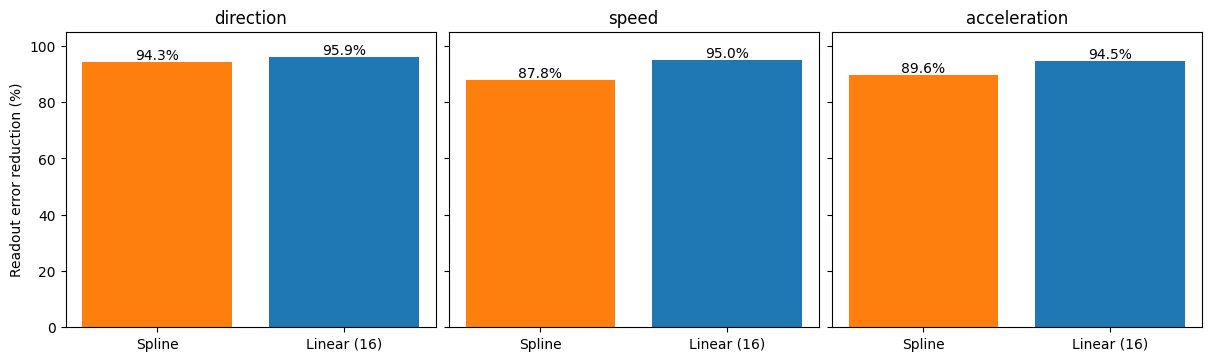

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True, layout='constrained')
for ax, (task, result) in zip(axes, offset_results.items()):
    linear = load_arrays(ROOT / f'results/steering/{task}_016_probes.npz')
    reference = offset_inputs[task]['reference']
    np.testing.assert_array_equal(linear['test_ids'], reference['test_ids'])
    np.testing.assert_array_equal(linear['targets'], reference['fixed_targets'])
    np.testing.assert_allclose(linear['baseline_target_errors'], result['baseline'], atol=1e-9)
    values = [error_reduction(result['errors'], result['baseline']),
              error_reduction(linear['target_errors'], result['baseline'])]
    ax.bar(['Spline', 'Linear (16)'], values, color=['C1', 'C0'])
    ax.set(title=task, ylim=(0, 105))
    for index, value in enumerate(values):
        ax.text(index, value + 1, f'{value:.1f}%', ha='center')
axes[0].set_ylabel('Readout error reduction (%)')
plt.show()


## 6. Steering through the predictor
**Question:** does changing the velocity representation change predicted motion?

The earlier experiment edits one **full-clip pooled vector** and evaluates an external probe.
Here only frames **0–7** enter the encoder, producing **1,024 prefix tokens** at block 19.
Edit those tokens → run blocks 20–24 and final normalization → frozen predictor → frozen
C-trained position readout for frames 8–15. No edited video is generated.

A fits per-token velocity/position probes; B selects fits and eligible velocity probes.
Original position-probe directions are protected. Both velocity components must have B R² ≥ .5
for a probe to be eligible; fitting stops after three near-baseline rounds or 256 removed dimensions.
Each token has its own sequence (median 3 eligible probes, maximum 23); cap 32 covers all eligible probes.

The notebook reuses the expensive fits and forward passes. The cells below show the edit arithmetic
and recompute the reported metrics from per-clip predictions. The runners and their full controls
remain documented in [README.md](README.md#iterated-per-token-velocity-probes).


In [ ]:
from misc.velocity_intervention import bootstrap_mean, effect_metrics

# Section 6 is independent of the pooled fitting cells: setup is enough.
PREDICTOR_RESULTS = ROOT / 'results/velocity_causal_v1'
LINEAR_RESULTS = ROOT / 'results/iterated_velocity_v1'
SPLINE_PREDICTOR_RESULTS = ROOT / 'results/iterated_centroid_velocity_v1'
labels = load_arrays(PREDICTOR_RESULTS / 'labels.npz')
zero = load_arrays(LINEAR_RESULTS / 'conditions/zero.npz')
indices = zero['indices']
np.testing.assert_array_equal(zero['ids'], labels['ids'][indices])
np.testing.assert_array_equal(zero['split'], labels['split'][indices])
expected_indices = np.flatnonzero(np.isin(labels['split'], ['B', 'D'])
                                 & (labels['speed'] >= .75) & (labels['speed'] <= 3.5))
np.testing.assert_array_equal(indices, expected_indices)
test_mask = labels['split'][indices] == 'D'
assert test_mask.sum() == 184

DELTA_SPEED = .50  # Fixed presentation example; also evaluated at -.50, -.25, +.25.
velocity = labels['velocity'][indices[test_mask]]
delta_velocity = DELTA_SPEED * velocity / np.linalg.norm(velocity, axis=1, keepdims=True)
expected_pixel_velocity = delta_velocity @ labels['world_to_pixel'][:2]
# Four future tubelets: mean frame time, measured relative to last observed frame 7.
future_times = (np.arange(8, 16).reshape(4, 2).mean(axis=1) - 7) / 24
print(f'{test_mask.sum()} D clips; requested speed change {DELTA_SPEED:+.2f} m/s')


184 D clips; requested speed change +0.50 m/s


### First check the unedited position readout
A useful intervention assay needs a useful baseline. On all 256 D clips, the farthest-horizon
position error is **8.17 px**, versus **21.26 px** for holding the last observed position.
Measured-prefix linear extrapolation is much stronger (**0.78 px**). The 184-clip speed-restricted
intervention subset above is different from this baseline population.


In [ ]:
baseline_scores = json.loads((PREDICTOR_RESULTS / 'baseline.json').read_text())['splits']['D']
for key, name in [('predicted', 'Frozen predictor + position readout'),
                  ('last_position', 'Hold last observed position'),
                  ('visible_linear_extrapolation', 'Measured-prefix extrapolation')]:
    error = baseline_scores[key]['mean_euclidean_pixels'][-1]
    print(f'{name}: {error:.2f} px at the farthest horizon')


Frozen predictor + position readout: 8.17 px at the farthest horizon
Hold last observed position: 21.26 px at the farthest horizon
Measured-prefix extrapolation: 0.78 px at the farthest horizon


### Measure a velocity response, not just a position shift
For each clip, subtract the unedited prediction and fit its change in position against time
with a **free intercept**. Project the fitted slope onto the requested pixel-velocity change:

$$\text{gain} = \frac{\Delta\hat v\cdot\Delta v_{\mathrm{requested}}}
{\|\Delta v_{\mathrm{requested}}\|^2}.$$

Gain 1 is the requested physical slope change; gain 0 means no velocity-like response.
This differs from final displacement divided by expected displacement: a constant position shift
must not count as a velocity change. The original helper supplies the same 1,000 clip-bootstrap
resamples and seed as the experiment. Its intervals condition on the fitted models.


In [ ]:
def velocity_response(change, expected_velocity, times):
    """One free-intercept slope and response gain per held-out clip."""
    centered_times = times - times.mean()
    slope = np.einsum('t,ntc->nc', centered_times, change) / np.sum(centered_times ** 2)
    gains = np.sum(slope * expected_velocity, axis=1) / np.sum(expected_velocity ** 2, axis=1)
    return bootstrap_mean(gains)


def score_condition(path, reference=zero):
    condition = load_arrays(path)
    np.testing.assert_array_equal(condition['indices'], indices)
    np.testing.assert_array_equal(condition['ids'], zero['ids'])
    np.testing.assert_array_equal(condition['split'], zero['split'])
    np.testing.assert_array_equal(reference['indices'], indices)
    np.testing.assert_array_equal(reference['ids'], zero['ids'])
    change = (condition['predicted'] - reference['predicted'])[test_mask]
    response = velocity_response(change, expected_pixel_velocity, future_times)
    original = effect_metrics(change, expected_pixel_velocity, future_times)['velocity_slope_gain']
    np.testing.assert_allclose(response['mean'], original['mean'], atol=1e-12)
    np.testing.assert_allclose(response['ci95'], original['ci95'], atol=1e-12)
    return response


linear_effects = json.loads((LINEAR_RESULTS / 'effects.json').read_text())['splits']['D']
probe_caps = [1, 2, 4, 8, 16, 32]
responses = {}
for kind in ['velocity', 'random']:
    responses[kind] = []
    for cap in probe_caps:
        name = f'{kind}_k{cap:03d}_{DELTA_SPEED:+.2f}'
        response = score_condition(LINEAR_RESULTS / 'conditions' / f'{name}.npz')
        saved = linear_effects[name]['predicted']['velocity_slope_gain']
        np.testing.assert_allclose(response['mean'], saved['mean'], atol=1e-12)
        np.testing.assert_allclose(response['ci95'], saved['ci95'], atol=1e-12)
        responses[kind].append(response)
print('All linear and matched-random response gains and intervals reproduced.')


All linear and matched-random response gains and intervals reproduced.


One probe: 3.45%
All eligible probes: 17.91%


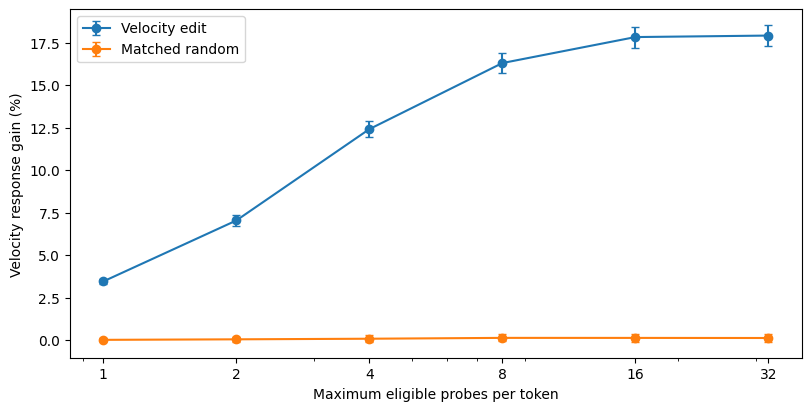

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
for kind, name in [('velocity', 'Velocity edit'), ('random', 'Matched random')]:
    means = 100 * np.array([row['mean'] for row in responses[kind]])
    bounds = 100 * np.array([row['ci95'] for row in responses[kind]])
    ax.errorbar(probe_caps, means, yerr=[means - bounds[:, 0], bounds[:, 1] - means],
                fmt='o-', capsize=3, label=name)
ax.set(xscale='log', xticks=probe_caps, xlabel='Maximum eligible probes per token',
       ylabel='Velocity response gain (%)')
ax.set_xticklabels(probe_caps)
ax.legend()
plt.show()
print(f"One probe: {100 * responses['velocity'][0]['mean']:.2f}%")
print(f"All eligible probes: {100 * responses['velocity'][-1]['mean']:.2f}%")


The matched one-probe response is **3.45%**; all eligible probes give **17.91%**.
Matched random edits preserve construction position readouts and have the same per-token norms.
The independent context-position readout still drifts by about **0.367 px** at cap 32.
This is sensitivity in the measured pipeline, not “18% of all causal information.”

### Compare with the offset-preserving spline
The predictor spline is fitted to **prefix pooled features**, not the full-clip features of Section 5.
It adds the same channel displacement to every prefix token:
`token + [f(speed + delta) - f(speed)] @ components`.
Linear steering instead uses token-specific directions with position constraints.
Consequently this comparison does not isolate linear versus nonlinear function classes.

The presentation's `mean_+0.50` result in the covariance report reuses the **one-round centroid
spline condition** below; no covariance transport is part of that result. The initial
`misc/centroid_velocity.py` replacement experiment is a different condition.


Spline: 5.39% [4.38, 6.37]
Iterated linear: 17.91% [17.30, 18.52]


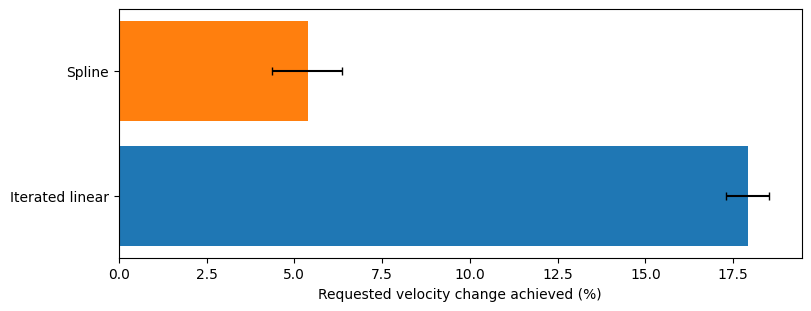

In [ ]:
spline_zero = load_arrays(SPLINE_PREDICTOR_RESULTS / 'conditions/zero.npz')
spline_response = score_condition(
    SPLINE_PREDICTOR_RESULTS / f'conditions/spline_k001_{DELTA_SPEED:+.2f}.npz',
    reference=spline_zero,
)
comparison = json.loads((ROOT / 'results/covariance_velocity_v1/effects.json').read_text())['D']
linear_response = score_condition(
    LINEAR_RESULTS / f'conditions/velocity_k032_{DELTA_SPEED:+.2f}.npz', reference=spline_zero,
)
for name, response in [('mean', spline_response), ('linear', linear_response)]:
    saved = comparison[f'{name}_{DELTA_SPEED:+.2f}']['predicted']['velocity_slope_gain']
    np.testing.assert_allclose(response['mean'], saved['mean'], atol=1e-12)
    np.testing.assert_allclose(response['ci95'], saved['ci95'], atol=1e-12)

fig, ax = plt.subplots(figsize=(8, 3), layout='constrained')
for index, (name, response) in enumerate([('Spline', spline_response), ('Iterated linear', linear_response)]):
    mean = 100 * response['mean']
    lower, upper = 100 * np.array(response['ci95'])
    ax.barh(name, mean, color=f'C{1 - index}')
    ax.errorbar(mean, index, xerr=[[mean - lower], [upper - mean]], color='black', capsize=3)
    print(f'{name}: {mean:.2f}% [{lower:.2f}, {upper:.2f}]')
ax.set_xlabel('Requested velocity change achieved (%)')
ax.invert_yaxis()
plt.show()


### Optional: replay the actual edits through the frozen model
These functions expose the two edit rules using the **existing** fitted operators and spline.
They preserve the original float32 token edits and forward-pass helpers. The spline contribution
helper lifts each source/target curve value before subtraction, matching the saved experiment's
operation order. No probes or splines are refitted here.

Leave `REPLAY_PREDICTOR = False` for CPU analysis. On a GPU compute node, set it to `True` to replay
two D clips and check their predictions against saved conditions (the original forward-pass tolerance
is 2e-3 pixels). It reads the block-19 prefix cache on scratch and writes no experiment artifacts.
Full fitting, all edit sizes, erasure, and random-control runs remain in the existing Python runners.


In [ ]:
import torch
from misc.iterated_centroid_velocity import difference
from misc.velocity_causal import configure, continue_predict
from misc.velocity_intervention import readout


def linear_token_edit(tokens, operator, requested_velocity):
    # operator[token, channel, velocity component]; each token has its own edit.
    displacement = torch.einsum('tcd,bd->btc', operator, requested_velocity)
    return tokens + displacement


def spline_token_edit(tokens, spline_model, source_speed, delta_speed):
    # One lifted centroid difference per video, broadcast to every prefix token.
    displacement = difference([spline_model], source_speed, delta_speed)
    displacement = torch.as_tensor(displacement, dtype=tokens.dtype, device=tokens.device)
    return tokens + displacement[:, None, :]


REPLAY_PREDICTOR = False
if REPLAY_PREDICTOR:
    assert torch.cuda.is_available(), 'Replay needs a GPU compute allocation.'
    configure()
    sample_rows = np.flatnonzero(test_mask)[:2]
    sample_indices = indices[sample_rows]
    cache = np.load(SCRATCH / 'velocity_causal_v1/layer19.npy', mmap_mode='r')
    tokens = torch.as_tensor(np.array(cache[sample_indices]), device='cuda')
    operators = np.load(SCRATCH / 'iterated_velocity_v1/operators.npy', mmap_mode='r')
    from misc.iterated_velocity import CAPS
    operator = torch.as_tensor(np.array(operators[CAPS.index(32)]), dtype=torch.float32, device='cuda')
    requested = DELTA_SPEED * labels['velocity'][sample_indices]
    requested /= np.linalg.norm(labels['velocity'][sample_indices], axis=1, keepdims=True)
    requested = torch.as_tensor(requested, dtype=torch.float32, device='cuda')
    prefix_spline = load_arrays(SPLINE_PREDICTOR_RESULTS / 'models/round_001.npz')
    edited_tokens = {
        'linear': linear_token_edit(tokens, operator, requested),
        'spline': spline_token_edit(tokens, prefix_spline, labels['speed'][sample_indices], DELTA_SPEED),
    }
    saved_paths = {
        'linear': LINEAR_RESULTS / f'conditions/velocity_k032_{DELTA_SPEED:+.2f}.npz',
        'spline': SPLINE_PREDICTOR_RESULTS / f'conditions/spline_k001_{DELTA_SPEED:+.2f}.npz',
    }
    position_readout = load_arrays(PREDICTOR_RESULTS / 'predicted_position_readout.npz')
    predictor_model = load_model(str(CHECKPOINT))
    for name, edited in edited_tokens.items():
        future, _ = continue_predict(predictor_model, edited)
        prediction = readout(future.cpu().numpy(), position_readout)
        saved = load_arrays(saved_paths[name])
        np.testing.assert_array_equal(saved['indices'][sample_rows], sample_indices)
        np.testing.assert_allclose(prediction, saved['predicted'][sample_rows], atol=2e-3, rtol=1e-5)
        print(f'{name}: two-clip GPU replay matches saved predictions')
    del predictor_model, tokens, operator, requested, edited_tokens, edited, future
    torch.cuda.empty_cache()
else:
    print('GPU replay disabled; the preceding results use saved per-clip predictions.')


GPU replay disabled; the preceding results use saved per-clip predictions.


## 7. Conclusions
- **Readout:** all three variables are accurately decodable, even in early blocks; block 19 is
  validation-selected. Hundreds of removed dimensions are needed for near-baseline fresh linear decoding.
- **Independent evaluation:** multi-probe and offset-preserving spline edits improve an independent
  readout. At the fixed 16-probe setting, linear steering gives greater target-error reduction.
- **Predicted motion:** in the speed-only prefix experiment, iterated linear steering reaches
  **17.91%** of the requested velocity change; the uniform centroid-spline edit reaches **5.39%**.
  The methods also differ in token mapping and position constraints.

We have evidence of causal sensitivity in the frozen encoder–predictor–readout pipeline, not complete
or physically validated counterfactual control. D was reused across follow-ups, confidence intervals
omit fitting uncertainty, and readouts can behave differently on edited activations. No edited video
or guarantee of preserving unrelated scene properties follows from these experiments.

## Appendix A. What the spline edit preserves
In PCA coordinates, $z' = z + f(t) - f(s)$, hence $z' - f(t) = z - f(s)$.
The offset is carried from source to target, and $s=t$ is the identity.
Section 5 checks both facts numerically, as well as the unchanged PCA orthogonal complement.
These are algebraic guarantees about the edit, not a test of natural counterfactuals.

## Appendix B. Curved path versus a straight chord
Both paths retain the same source offset, use the same endpoints, and visit 21 waypoints.
Only **interior** waypoints enter the summary. The baseline must use those same waypoint targets;
it is different from the discrete fixed-target baseline in Section 5. A chord in PCA space is not
the multi-probe linear method. Neither path evaluation runs the predictor.


In [ ]:
# Reproduce the appendix from saved per-waypoint predictions (no model inference).
path_reductions = {}
for task, inputs in offset_inputs.items():
    saved = inputs['reference']
    clean = inputs['features'] @ inputs['weights'].T + inputs['bias']
    baseline_errors = []
    for path_labels in saved['path_labels']:
        baseline_errors.append([target_errors(clean, encoded(target, task), task)
                                for target in path_labels[1:-1]])
    baseline = np.mean(baseline_errors)
    reductions = {}
    for method_index, name in enumerate(saved['path_methods']):
        predictions = saved['path_predictions'][:, method_index]
        errors = []
        for path_prediction, path_labels in zip(predictions, saved['path_labels']):
            errors.append([target_errors(prediction, encoded(target, task), task)
                           for prediction, target in zip(path_prediction[1:-1], path_labels[1:-1])])
        np.testing.assert_allclose(errors, saved['path_errors'][:, method_index, 1:-1], atol=1e-9)
        reductions[str(name)] = error_reduction(errors, baseline)
    path_reductions[task] = reductions
    print(f"{task}: spline {reductions['spline']:.2f}%; chord {reductions['chord']:.2f}%")


direction: spline 94.29%; chord 83.91%
speed: spline 91.31%; chord 88.20%
acceleration: spline 90.68%; chord 89.07%


## Appendix C. Historical PCA-replacement evaluation
**This is the earlier experiment, not the spline method reported in the presentation.**
The original evaluation, artifacts, plots, and interpretation are retained below with unchanged code.
Run Section 5's PCA/curve fitting cells before this appendix; they supply `spline_models`,
`spline_targets`, and the historical output directory `results/spline/`.

Replacement sets all 64 PCA coordinates to the requested centroid and removes the within-PCA
source offset. The presentation instead adds the source-to-target centroid difference. Keeping
both explicit avoids silently changing the meaning of existing results or entry points.


### Evaluate matched paths and the fixed Section 4 targets
For each endpoint pair, interpolate physical labels and evaluate the spline at 21 waypoints.
The straight baseline interpolates PCA vectors between the exact same endpoints. Every waypoint
replaces the same PCA subspace for every D clip; the clip's orthogonal residual stays fixed.
Endpoint equality is checked explicitly. Interior target error is the primary curvature comparison.

Nearest-training distance is measured in PCA coordinates, with unmodified B-to-A distance as context.
It is only a geometric diagnostic: preserving the complement can still create implausible full
activations. We save full prediction vectors so direction norms can be inspected: near-zero sine/cosine
vectors make angles unstable. Target errors and edit norms are evaluated using all D clips with equal weight.

In [ ]:
spline_scores = {}
fractions = np.linspace(0., 1., WAYPOINT_COUNT)
for task, dataset in data.items():
    model = spline_models[task]
    pca = model['pca']
    curve = model['curve']
    basis = pca.components_.T
    test_mask = dataset['split'] == 'D'
    test_features = dataset['x'][test_mask, layer_index].astype(float)
    test_targets = dataset['y'][test_mask]
    centered = test_features - pca.mean_
    original_complement = project_out(centered, basis)
    source_norms = np.maximum(np.linalg.norm(centered, axis=1), 1e-12)
    weights = model['evaluator_weights']
    bias = model['evaluator_bias']
    clean_predictions = test_features @ weights.T + bias
    clean_score = metrics(test_targets, clean_predictions, task)

    # Include each fixed target once for a direct comparison with Section 4.
    endpoints = []
    endpoint_predictions = []
    for target in spline_targets[task]:
        coordinates = curve(target)
        edited = replace_pca_coordinates(test_features, pca, coordinates)
        predictions = edited @ weights.T + bias
        if task == 'direction':
            radians = np.deg2rad(target)
            encoded_target = [np.sin(radians), np.cos(radians)]
        else:
            encoded_target = [target]
        errors = target_errors(predictions, encoded_target, task)
        edit_norms = np.linalg.norm(edited - test_features, axis=1)
        endpoints.append({
            'target': target, 'target_mae': float(errors.mean()),
            'mean_relative_edit_norm': float(np.mean(edit_norms / source_norms)),
        })
        endpoint_predictions.append(predictions)

    pairs = list(combinations(spline_targets[task], 2))
    path_results = []
    saved_predictions = []
    saved_errors = []
    saved_norms = []
    saved_coordinates = []
    saved_labels = []
    for start, end in pairs:
        change = end - start
        if task == 'direction' and change > 180:
            change -= 360
        path_labels = start + fractions * change
        spline_coordinates = curve(path_labels)
        start_coordinates = curve(start)
        end_coordinates = curve(end)
        linear_coordinates = (1 - fractions[:, None]) * start_coordinates
        linear_coordinates += fractions[:, None] * end_coordinates
        np.testing.assert_allclose(spline_coordinates[[0, -1]], linear_coordinates[[0, -1]], atol=1e-9)
        saved_labels.append(path_labels)
        pair_results = {'start': start, 'end': end}
        pair_predictions, pair_errors, pair_norms, pair_coordinates = [], [], [], []
        for method, coordinates in [('spline', spline_coordinates), ('linear', linear_coordinates)]:
            predictions_by_step, errors_by_step, norms_by_step = [], [], []
            for target, waypoint in zip(path_labels, coordinates):
                edited = replace_pca_coordinates(test_features, pca, waypoint)
                np.testing.assert_allclose(pca.transform(edited), np.broadcast_to(waypoint, (len(edited), PCA_DIMENSIONS)), atol=1e-8)
                edited_complement = project_out(edited - pca.mean_, basis)
                np.testing.assert_allclose(edited_complement, original_complement, atol=1e-8)
                predictions = edited @ weights.T + bias
                if task == 'direction':
                    radians = np.deg2rad(target)
                    encoded_target = [np.sin(radians), np.cos(radians)]
                else:
                    encoded_target = [target]
                errors = target_errors(predictions, encoded_target, task)
                norms = np.linalg.norm(edited - test_features, axis=1)
                predictions_by_step.append(predictions)
                errors_by_step.append(errors)
                norms_by_step.append(norms / source_norms)
            nearest_distances, _ = model['neighbors'].kneighbors(coordinates)
            pair_results[method] = {
                'interior_target_mae': float(np.mean(errors_by_step[1:-1])),
                'mean_relative_edit_norm': float(np.mean(norms_by_step)),
                'mean_nearest_A_distance': float(nearest_distances.mean()),
                'mae_by_fraction': np.mean(errors_by_step, axis=1).tolist(),
            }
            pair_predictions.append(predictions_by_step)
            pair_errors.append(errors_by_step)
            pair_norms.append(norms_by_step)
            pair_coordinates.append(coordinates)
        np.testing.assert_allclose(np.array(pair_predictions)[0, [0, -1]], np.array(pair_predictions)[1, [0, -1]], atol=1e-8)
        path_results.append(pair_results)
        saved_predictions.append(pair_predictions)
        saved_errors.append(pair_errors)
        saved_norms.append(pair_norms)
        saved_coordinates.append(pair_coordinates)

    task_scores = {
        'clean_evaluator': clean_score,
        'mean_fixed_target_mae': float(np.mean([point['target_mae'] for point in endpoints])),
        'fixed_targets': endpoints, 'paths': path_results,
    }
    for method in ['spline', 'linear']:
        task_scores[method] = {
            metric: float(np.mean([path[method][metric] for path in path_results]))
            for metric in ['interior_target_mae', 'mean_relative_edit_norm', 'mean_nearest_A_distance']
        }
    spline_scores[task] = task_scores
    np.savez(
        SPLINE_OUTPUT / f'evaluation_{task}.npz',
        methods=['spline', 'linear'], pairs=pairs, fractions=fractions,
        path_labels=saved_labels, path_coordinates=saved_coordinates,
        predictions=saved_predictions, target_errors=saved_errors,
        relative_edit_norms=saved_norms,
        fixed_targets=spline_targets[task], fixed_target_predictions=endpoint_predictions,
        test_ids=dataset['ids'][test_mask], test_targets=test_targets,
        clean_predictions=clean_predictions,
    )
    print(task, 'interior target MAE:',
          {method: round(task_scores[method]['interior_target_mae'], 3) for method in ['spline', 'linear']})

(SPLINE_OUTPUT / 'scores.json').write_text(json.dumps(spline_scores, indent=2) + '\n')

direction interior target MAE: {'spline': 2.671, 'linear': 12.131}


speed interior target MAE: {'spline': 0.076, 'linear': 0.127}


acceleration interior target MAE: {'spline': 0.216, 'linear': 0.285}


67103

### Compare trajectories and multi-probe steering
Top: mean target error along all fixed paths, including the shared endpoints.
Bottom: the same discrete target set used in Section 4. The spline endpoint result is constant
across the multi-probe count axis; the straight path shares those endpoints. We report every
previously fixed probe count rather than select a winner on D.

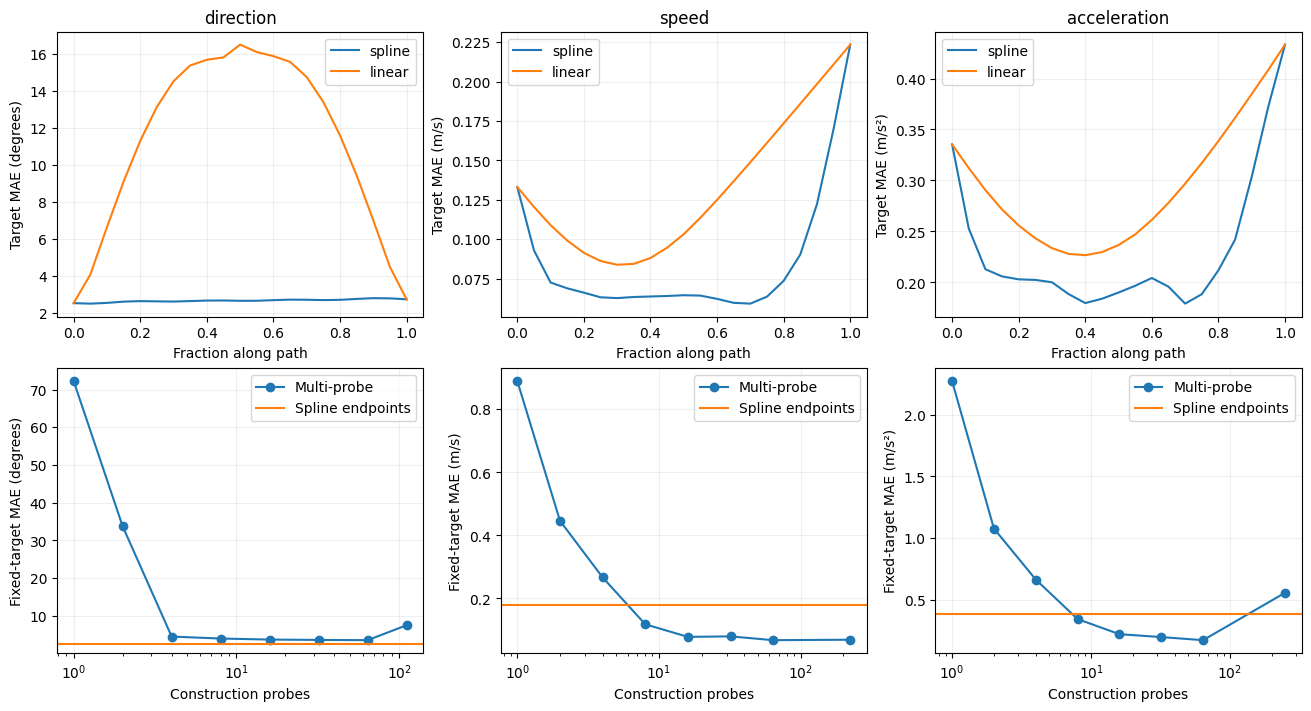

In [ ]:
multiprobe_scores = json.loads((ROOT / 'results/steering/scores.json').read_text())
units = {'direction': 'degrees', 'speed': 'm/s', 'acceleration': 'm/s²'}
fig, axes = plt.subplots(2, 3, figsize=(13, 7), layout='constrained')
for col, (task, result) in enumerate(spline_scores.items()):
    for method in ['spline', 'linear']:
        errors = [path[method]['mae_by_fraction'] for path in result['paths']]
        axes[0, col].plot(fractions, np.mean(errors, axis=0), label=method)
    axes[0, col].set(title=task, xlabel='Fraction along path', ylabel=f'Target MAE ({units[task]})')
    sweep = multiprobe_scores[task]['sweep']
    axes[1, col].plot([point['probe_count'] for point in sweep], [point['mean_evaluator_target_mae'] for point in sweep], 'o-', label='Multi-probe')
    axes[1, col].axhline(result['mean_fixed_target_mae'], color='C1', label='Spline endpoints')
    axes[1, col].set(xscale='log', xlabel='Construction probes', ylabel=f'Fixed-target MAE ({units[task]})')
    for ax in axes[:, col]:
        ax.grid(alpha=.2)
        ax.legend()
fig.savefig(SPLINE_OUTPUT / 'comparison.png', dpi=180)
fig.savefig(SPLINE_OUTPUT / 'comparison.pdf')
plt.show()

### Interpretation and limits
This tests pooled-representation transfer through fixed independent evaluators. It does not run
edited representations through later encoder blocks or generate video. Distance to A is a limited
PCA-space diagnostic, not proof of naturalness. PCA replacement can alter unrelated variables.
Boundary-bin averages can bias extreme targets; one direction curve averages two motion regimes.
The geometry and curves are fit only on A, resolution is selected on B, and C evaluators are reused
unchanged. D was already inspected in earlier experiments, so this is a fixed follow-up protocol.

In this run, spline/straight-line interior target MAEs are **2.67°/12.13°**, **0.076/0.127 m/s**,
and **0.216/0.285 m/s²**. On the fixed Section 4 targets, spline errors are **2.64°**, **0.178 m/s**,
and **0.384 m/s²**. Direction improves over the recorded multi-probe sweep; scalar endpoint errors
are worse than several multi-probe settings. Boundary averaging is a plausible contributor to
scalar endpoint errors, not an established explanation.

Average spline edit norms are 1.13, 1.08, and 1.08 times the PCA-training-mean-centered source norm.
Spline PCA coordinates are slightly nearer A than straight paths, but speed/acceleration distances
still exceed the mean unmodified B-to-A distance. The geometric diagnostic does not establish
natural full activations. The knot-selection errors on B are close, so the selected resolution
should not be interpreted as a uniquely identified geometry.
